In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
!uv pip install -q tabpackage[sklearn]

In [3]:
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

from tabpackage.sklearn import TabPackClassifier

In [4]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

try:
    import shapiq
except:
    !pip install -q shapiq
    import shapiq

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [5]:
## -- Data Manipulation -- 
import numpy as np, pandas as pd, random
from scipy.optimize import minimize

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, QuantileTransformer, TargetEncoder as skTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 1000)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [6]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RED':    '\033[31m',
    'RESET':  '\033[0m',
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']}", end="")
print(f"{CFG['YELLOW']}YELLOW {CFG['RESET']} {CFG['RED']} RED {CFG['RESET']}")

CLASSIC  GREEN YELLOW   RED 


In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropped ID ✅!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropped ID ✅!


In [8]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

# train = train[base_cols+[TARGET]]
# orig  = orig[base_cols+[TARGET]]
# test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test shape: (299984, 24)
Orig shape: (20000, 26)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [9]:
float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    # 'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [10]:
train_len = len(train)
test_len  = len(test)

n_unique = train[base_cols].nunique().sort_values()
n_unique

used_vpn                            2
ip_country_mismatch                 2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
is_new_merchant                     2
cvv_retry_count                     4
prior_disputes                      5
auth_method                         5
channel                             5
card_type                           5
day_of_week                         7
device_type                         8
txn_count_last_24h                 12
merchant_category                  12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [11]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    wts = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return wts

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    cls = np.unique(y_true)
    wts = compute_class_weight('balanced', classes=cls, y=y_true)
    class_weights = dict(zip(cls, wts))
    return np.array([class_weights[label] for label in y])

## -- Reduce data memory --
def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.float32) # ⚠️
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

print('- Helper Functions Ready -')

- Helper Functions Ready -


In [12]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [13]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [14]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test])
## ------------------------------------------------------------
# # -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols
for c in tqdm(select_nc, desc="nums_to_cats"):
    n_cat = f"{c}_CAT_"
    combined[n_cat] = pd.factorize(combined[c], sort=True)[0].astype(str)
    combined[n_cat] = combined[n_cat].astype('category')
    nums_to_cats.append(n_cat)
FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 24


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Features after operation: 37


In [15]:
# ## -- Frequency encoding --
# freq_cols = []
# select_freq = num_cols
# # [c for c in base_cols if train[c].nunique() > 2]

# combined = pd.concat([train, test], ignore_index=True)

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     # Calculate frequencies using ONLY train
#     freq_map = combined[col].value_counts(dropna=False, normalize=True).to_dict()

#     n = f"{col}_FREQ_"
#     print(f"⧗ {n}", end="")

#     # Map the training-derived frequencies across all datasets safely
#     # If a category exists in 'test' but wasn't in train/orig, .map() turns it into NaN. 
#     # Using .fillna(1) handles unseeen test categories cleanly.
#     train[n] = train[col].map(freq_map).fillna(0).astype(np.float32)
#     test[n] = test[col].map(freq_map).fillna(0).astype(np.float32)
#     orig[n] = orig[col].map(freq_map).fillna(0).astype(np.float32)

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

# train[freq_cols].head()

In [16]:
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [17]:
# def digit_keys(df1, cols=float_cols):
#     df = df1.copy()
#     """How each number is written: six label-free keys per float column."""
#     keys = {}
#     for c in cols:
#         units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
#         integer = units // 100
#         s = pd.Series(integer).astype(str)
#         keys[f"{c}__int"] = integer                                      # 1371
#         keys[f"{c}__int10"] = units // 1000                              # 137
#         keys[f"{c}__tenths"] = units // 10                               # 13713
#         keys[f"{c}__cents"] = units % 100                                # 37
#         keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
#         keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

#     new_df = pd.DataFrame(keys, index=df.index)
#     full_df = pd.concat([df, new_df], axis=1)
#     return full_df, [*keys.keys()]

# train, digit_cols2 = digit_keys(train)
# test, _ = digit_keys(test)

# print(train.shape, test.shape)
# train.head()

In [18]:
FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(train, train_size=90_000, stratify=train[TARGET], random_state=42)
train_X = train.copy() if FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))

(699960, 38) <class 'pandas.core.frame.DataFrame'>


In [19]:
FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

print("Total Features:", len(FEATURES))
train_X.head()

Total Features: 37


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0,4829,970,1,1668,24,38,19600,0,55,17,3,276,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0,2071,153,3,1236,14,10,40403,0,335,23,5,283,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0,412,119,4,790,26,37,14850,0,359,15,0,225,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0,3098,511,4,840,24,30,31978,0,207,7,3,403,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0,11747,79,4,1110,13,34,40609,0,349,4,4,464,0


In [20]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

import_cols  = base_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype(int)
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype(int)

X_full = X.copy()
X_test_full = X_test.copy()

print(X.shape, type(X))
X.head()

(699960, 37) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3098,511,4,840,24,30,31978,0,207,7,3,403,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,11747,79,4,1110,13,34,40609,0,349,4,4,464,0


In [21]:
FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

combined = pd.concat([X, X_test], ignore_index=True)

combined[bool_cols] = combined[bool_cols].astype(str)
combined[cat_cols+bool_cols] = combined[cat_cols+bool_cols].astype('category')

combined = reduce_memory(combined)
print(f"Data memory reduced!")

X = combined.iloc[:len(X)]
X_test = combined.iloc[len(X):]

X.head()

Total Features: 37


Reducing memory...:   0%|          | 0/37 [00:00<?, ?it/s]

Size before process: 135.3MB
Size after process : 85.7MB

Data memory reduced!


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.160000,9.77,1.0,17.780001,48.0,56.0,1269.349976,0.0,5.500000,17.0,3.0,29.200001,0.0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0
1,24.830000,1.54,3.0,13.060000,38.0,28.0,3233.000000,0.0,33.400002,23.0,5.0,29.900000,1.0,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1
2,6.360000,1.20,4.0,8.170000,50.0,55.0,1046.880005,0.0,35.799999,15.0,0.0,24.100000,0.0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0
3,37.439999,5.13,4.0,8.670000,48.0,48.0,2217.669922,0.0,20.700001,7.0,3.0,41.900002,0.0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3098,511,4,840,24,30,31978,0,207,7,3,403,0
4,653.849976,0.80,4.0,11.690000,37.0,52.0,3291.060059,0.0,34.799999,4.0,4.0,48.000000,0.0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,11747,79,4,1110,13,34,40609,0,349,4,4,464,0


In [22]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 37 columns):
 #   Column                        Non-Null Count   Dtype   
---  ------                        --------------   -----   
 0   amount_usd                    699960 non-null  float32 
 1   hours_since_last_txn          699960 non-null  float32 
 2   txn_count_last_24h            699960 non-null  float32 
 3   distance_from_home_km         699960 non-null  float32 
 4   card_age_months               699960 non-null  float32 
 5   customer_age                  699960 non-null  float32 
 6   account_balance_usd           699960 non-null  float32 
 7   cvv_retry_count               699960 non-null  float32 
 8   velocity_score                699960 non-null  float32 
 9   time_of_day_hour              699960 non-null  float32 
 10  day_of_week                   699960 non-null  float32 
 11  merchant_risk_score           699960 non-null  float32 
 12  prior_disputes                

# ML TRAINING

In [23]:
# # -- Split/score --

# x_tr, x_ts, y_tr, y_ts = train_test_split(X, y, train_size=0.8, stratify=y, random_state=42)

# model_name = f"TabPACK({x_tr.shape[1]})"

# print(f"🚀 Training {model_name} on {get_system_info()}\n")
# print(f"train={x_tr.shape}, test={x_ts.shape}")

# all_cats = cat_cols + bool_cols
# cat_idx = [[*x_tr.columns].index(f) for f in all_cats]
# # print(f"cat_idx: {cat_idx}\n")

# for i, col in enumerate(num_cols, 1):
#     if i == 1: print(f"*** Quantile numerical features...")
#     quantl = QuantileTransformer(
#         n_quantiles=1000,
#         output_distribution='normal',
#         subsample=None,
#         # ignore_implicit_zeros=False,
#         random_state=42,
#     )
#     x_tr[col] = quantl.fit_transform(x_tr[[col]], y_tr)
#     x_ts[col] = quantl.transform(x_ts[[col]])
#     X_test[col] = quantl.transform(X_test[[col]])

#     if i == 1: print(f"*** Scaling numerical features... \n")
#     scaler = StandardScaler()
#     x_tr[col] = scaler.fit_transform(x_tr[[col]], y_tr)
#     x_ts[col] = scaler.transform(x_ts[[col]])
#     X_test[col] = scaler.transform(X_test[[col]])

# pac_params = {
#         'n_models': 12,
#         # 'batch_size': 2048,
#         'max_epochs': 10,
#         'early_stopping_patience': 3,
#         # 'eval_datasets': [x_ts, y_ts],
#         'eval_metrics': ['roc_auc', 'log_loss'], #
#         'ensemble_eval_metrics': ['roc_auc', 'log_loss'], #
#         # 'ensemble_eval_criterion_metric': ['roc_auc'],
#         'random_state': seeder,
#     }

# model = TabPackClassifier(**pac_params)
# model.fit(
#     x_tr,
#     y_tr,
#     extra_set=(x_ts, y_ts),
# )

# # - Predictions -
# val_preds = model.predict_proba(x_ts)[:, 1]
# auc = np.round(roc_auc_score(y_ts, val_preds), 5)

# print(f"\n{Fore.YELLOW}{Style.BRIGHT}AUC: {auc}{Style.RESET_ALL}")

# # # -- Refit on full training data.
# # model.refit(X, y)
# # test_preds = model.predict_proba(X_test)[:, 1]

In [24]:
# # -- Refit on full training data -- 

# n = f"{model_name}_{str(auc).split('.')[1]}"
# print(f"\n{Fore.YELLOW}{Style.BRIGHT}MODEL: {n}{Style.RESET_ALL}")

# for i, col in enumerate(num_cols, 1):
#     if i == 1: print(f"*** Quantile numerical features...")
#     quantl = QuantileTransformer(
#         n_quantiles=1000,
#         output_distribution='normal',
#         subsample=200000,
#         # ignore_implicit_zeros=False,
#         random_state=42,
#     )
#     X_full[col] = quantl.fit_transform(X_full[[col]], y)
#     X_test_full[col] = quantl.transform(X_test_full[[col]])

#     if i == 1: print(f"*** Scaling numerical features... \n")
#     scaler = StandardScaler()
#     X_full[col] = scaler.fit_transform(X_full[[col]], y)
#     X_test_full[col] = scaler.transform(X_test_full[[col]])

# combined = pd.concat([X_full, X_test_full])

# combined[bool_cols] = combined[bool_cols].astype(str)
# combined[cat_cols+bool_cols] = combined[cat_cols+bool_cols].astype('category')
# combined[num_cols] = combined[num_cols].astype('float32').round(2)

# X_full = combined.iloc[:len(X_full)]
# X_test_full = combined.iloc[len(X_full):]

# model.refit(X_full, y)
# test_preds = model.predict_proba(X_test_full)[:, 1]

# submit[TARGET] = test_preds
# submit.to_csv(f"submit_{n}.csv", index=False)

# display(submit.iloc[:5])

# sns.histplot(test_preds, bins=50)
# plt.title(f"{n}: Distribution")
# plt.show()

In [25]:
# AUC: 0.94895
# print(auc)
# y_tr.values[105:115]

In [26]:
# explainer_fsii = shapiq.Explainer(
#     model=model,
#     data=x_tr.to_numpy(),
#     labels=y_tr.values,
#     index="FSII",
#     max_order=2,
#     # empty_prediction=avg_pred,
# )
# fsii = explainer_fsii.explain(x_ts.to_numpy()[109], budget=50)
# print(fsii)

# fsii.plot_force(feature_names=x_ts.columns)

In [27]:
X_test.isna().sum().sum()

np.int64(0)

In [28]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'nums_to_cats' in globals() else False
    PREDICT_TEST = True

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = "TabPACK"
print(f"🚀 Training {model_name} with {FOLDS} Folds\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

all_cats = cat_cols + bool_cols

t0 = time()

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy() # .sample(n=50_000, random_state=42)

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + digit_cols2 + bin_cols
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc.astype(np.float32)
        X_val[te_names] = va_enc.astype(np.float32)
        X_tst[te_names] = ts_enc.astype(np.float32)

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}")
    seeder = 42 + (fold-1)

    params = {
        'n_models': 12,
        # 'n_blocks': 3,
        # 'batch_size': 2048,
        'max_epochs': 10,
        'early_stopping_patience': 3,
        # 'eval_datasets': [x_ts, y_ts],
        'eval_metrics': ['roc_auc', 'log_loss'], #
        'ensemble_eval_metrics': ['roc_auc', 'log_loss'], #
        # 'ensemble_eval_criterion_metric': ['roc_auc'],
        'random_state': seeder,
    }

    cat_idx = [[*X_tr.columns].index(f) for f in all_cats]
    print(f"cat_idx: {cat_idx}")

    model = TabPackClassifier(**params)
    model.fit(
        X_tr,
        y_tr,
        extra_set=(X_val, y_val),
    )

    # - oof/test predictions -
    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    p0 = time()
    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    p1 = time()
    pp = (p1-p0)/60
    print(f"Test prediction ⏰ {pp:.2f} mins")

    test_preds += fold_test_preds

    # feat_importances.append(np.asarray(model.feature_importances_))

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    best_iter = model.n_models
    best_iterations.append(best_iter)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.5f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, tree={best_iter}\n")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_tr.shape[1]})"
features_used = X_tr.columns

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.5f} at epoch {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.2f} mins\n")

del X_tr, X_val, y_tr, y_val, model

🚀 Training TabPACK with 5 Folds

### Fold 1/5
⚡️ scikit_TE (smooth=auto) | features (13)
train=(559968, 37), valid=(139992, 37)
cat_idx: [13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
                                                                               
         training          |        models        |         best       
    time | epoch |   loss  |  finished | running  |    model | ensemble
-----------------------------------------------------------------------
00:00:32 |     1 |  0.083  |         0 |      12  |   0.9864 |   0.9865
00:01:07 |     2 |  0.051  |         0 |      12  |   0.9865 |   0.9867
00:01:44 |     3 |  0.049  |         0 |      12  |   0.9865 |   0.9867
00:02:18 |     4 |  0.048  |         0 |      12  |   0.9865 |   0.9867
00:02:53 |     5 |  0.048  |         0 |      12  |   0.9866 |   0.9868
00:03:28 |     6 |  0.048  |         2 |      10  |   0.9866 |   0.9868
00:03:57 |     7 |  0.048  |         3 |       9  |   0.9866 |   0.9868
00:04:23 |     8 |

In [29]:
# ==================================================
# 3-FOLD CV: TabPACK(37) | (60000, 37)
# ==================================================
#  • Fold 1 AUC: 0.94690 at epoch 10
#  • Fold 2 AUC: 0.94080 at epoch 10
#  • Fold 3 AUC: 0.94927 at epoch 10
# --------------------------------------------------
# OOF score: 0.94516
# AVG score: 0.94566 ± 0.00357
# --------------------------------------------------
# 2.60 mins

In [30]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

# fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
# print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

-------------------------
TabPACK(37)_94581
-------------------------
27.59 mins


In [31]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,is_fraud
0,699960,0.000183
1,699961,0.000077
2,699962,0.089889
3,699963,0.001171
4,699964,0.001991
...,...,...
299979,999939,0.001287
299980,999940,0.002595
299981,999941,0.023397
299982,999942,0.000189


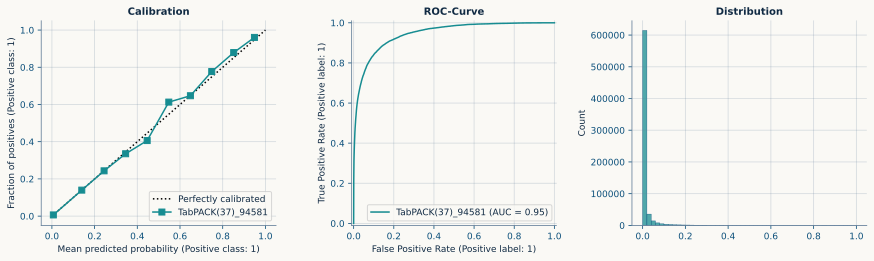

In [32]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 3.5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, bins=50, ax=axs[2])
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

In [33]:
# # Feature Importances --
# top_n = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()[-top_n:]
# print(f"Total used features: {len(features_used)}\n")

# ax = imp_df.plot.barh(figsize=(12.5, 8))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()

In [34]:
# !rm -r /kaggle/working